# LABORATORIO DIRIGIDO N.° 07

**Semana 7 · Aprendizaje no supervisado: clustering con K-Means**  
Segmentación del conjunto Auto MPG con K-Means, método del codo y silueta, y registro de los segmentos en SQLite, para el caso AutoFlota Andina  
Curso: Fundamentos de Gestión de Datos · Periodo: 2026-II · Docente: Pilar Rocío Sayán Mejía  
**Estudiante:** Erick Pariona Yauricasa · **Código:** 1421035 · **Sección:** C24-A  
Datos: `auto-mpg.data` (UCI Machine Learning Repository, dataset Auto MPG)

## Actividad 1 - Revisión de conceptos

Complete la tabla con definiciones elaboradas con sus propias palabras. No se admite la reproducción literal de fuentes externas ni de sistemas generativos.

| Concepto | Definición con sus propias palabras | Pregunta de apoyo |
|---|---|---|
| Aprendizaje supervisado y no supervisado | En el aprendizaje supervisado se cuenta con datos etiquetados (variable objetivo conocida, como el rendimiento en la regresión) y el modelo aprende la función para predecirla. En el no supervisado no existe variable objetivo ni etiquetas previas: el algoritmo analiza la estructura intrínseca de los datos y descubre patrones, agrupaciones o asociaciones naturales entre observaciones semejantes. | En la semana 6 se predijo el rendimiento. ¿Qué cambia hoy si no hay una variable objetivo? Den un ejemplo de cada tipo. |
| Segmentación (clustering) | Es la técnica no supervisada de dividir un conjunto heterogéneo de datos en subgrupos homogéneos internamente (alta cohesión) y heterogéneos entre sí (alta separación). En AutoFlota Andina permite ordenar la oferta vehicular en tipos de uso claros (urbano, mixto, carga) para planificar adquisiciones eficientes. | ¿Qué significa que los autos de un grupo se parezcan entre sí y se diferencien de los otros? ¿Para qué sirve esto en AutoFlota Andina? |
| Escalado con StandardScaler | Transformación estadística z-score que resta la media y divide entre la desviación estándar de cada variable cuantitativa, otorgando a todas media 0 y varianza 1. Es imprescindible antes de medir distancias euclidianas para evitar que variables con cifras elevadas (como el peso en miles de libras) monopolicen el cálculo y anulen variables con magnitudes menores (como la aceleración). | El peso va de 1 600 a 5 100 y la aceleración de 8 a 25. ¿Por qué hay que escalar antes de calcular distancias? |
| K-Means: centroides e iteraciones | Algoritmo iterativo de particionamiento que distribuye los datos en k grupos representados por sus centroides (vectores promedio). En cada iteración asigna cada registro al centroide más próximo y recalcula la posición de cada centroide como el promedio de sus miembros; el proceso se detiene cuando las asignaciones dejan de cambiar (convergencia) o se alcanza el número máximo de ciclos. | ¿Qué hace K-Means en cada iteración y cuándo se detiene? |
| Inercia y método del codo | La inercia es la suma de las distancias euclidianas al cuadrado de cada observación a su centroide asignado (WCSS) y evalúa la compacidad de los grupos. Siempre decrece al subir k porque los puntos tienen más centros cercanos. El método del codo grafica la inercia frente a k y busca el punto de inflexión donde la ganancia deja de ser pronunciada, señalando el límite de rendimientos decrecientes. | ¿Por qué la inercia siempre baja al aumentar k y cómo se usa entonces el codo para elegir k? |
| Silueta y perfil del segmento | El coeficiente de silueta mide (entre -1 y 1) la calidad del agrupamiento comparando la cohesión intra-cluster contra la separación al cluster vecino más cercano (valores cercanos a 1 indican grupos compactos y aislados). El perfil del segmento es el vector promedio de las variables en sus unidades originales de escala, lo cual permite caracterizar el grupo y adjudicarle un nombre intuitivo para la toma de decisiones de negocio. | ¿Qué indica una silueta cercana a 1 y cómo se convierte un grupo numérico en un segmento con nombre de negocio? |
| CRISP-DM | Marco metodológico estándar de minería de datos estructurado en 6 fases iterativas: 1) Comprensión del negocio, 2) Comprensión de los datos, 3) Preparación de los datos, 4) Modelado, 5) Evaluación y 6) Despliegue. El ajuste de K-Means (km.fit) corresponde a la Fase 4: Modelado. | ¿Cuáles son las seis fases y en cuál de ellas se ubica el ajuste de K-Means de hoy? |

## Actividad 2 - Desarrollo práctico y ejecución

### Caso de estudio: AutoFlota Andina (continuación)

AutoFlota Andina ya limpió sus datos y estimó el rendimiento de sus autos. Ahora necesita ordenar la oferta de vehículos en tipos, para decidir la compra por tipo de uso. Como nadie ha etiquetado los autos en grupos, el equipo de datos aplica un método no supervisado: K-Means agrupa los autos que se parecen en peso, potencia, aceleración y rendimiento.

> **Naturaleza de los datos.** Conjunto real e histórico del repositorio UCI Machine Learning Repository (Auto MPG, Quinlan, 1993) con 398 vehículos de los años de modelo 1970 a 1982, el mismo de las semanas 5 y 6. AutoFlota Andina es un caso ilustrativo. Los datos sirven para practicar segmentación, no para elegir vehículos actuales.

Variables: se usan peso (libras), potencia (hp), aceleracion (segundos de 0 a 60 mph) y rendimiento_mpg. No hay variable objetivo: el modelo descubre los grupos. Los nombres están en español, como en las semanas anteriores.

La tabla autos_limpio de SQLite guarda el resultado de la limpieza de la semana 6 y, al final del laboratorio, recibe una columna nueva con el segmento de cada auto.

**Recorrido CRISP-DM.** Cada parte del laboratorio corresponde a una fase del proceso CRISP-DM; las fases son iterativas.

| Fase CRISP-DM | Dónde está en este laboratorio |
|---|---|
| 1. Comprensión del negocio | Caso de estudio: ordenar la oferta en tipos de auto para decidir la compra. |
| 2. Comprensión de los datos | Celdas 1 y 2: tabla autos_limpio y descripción de las variables. |
| 3. Preparación de los datos | Celdas 2 y 3: elección de variables y escalado con StandardScaler. |
| 4. Modelado | Celdas 4 y 7: ajuste de K-Means. |
| 5. Evaluación | Celdas 5, 6, 8 y 9: codo, silueta, perfiles y gráfico. |
| 6. Despliegue | Celdas 10 y 11: registro en SQLite y asignación de los candidatos. |
| Iteración | Retos 1 a 3: se vuelve a la preparación y al modelado para comprobar las decisiones. |

### Preparación del entorno

Abra el notebook en Google Colab y ejecute la celda 1: importa las librerías, descarga el archivo desde UCI, repite la limpieza de la semana 6 (potencia imputada con la mediana, origen y año corregidos), la guarda en autos_limpio y la lee con pd.read_sql_query().

**Celda 1 de 14**

In [1]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Auto MPG de UCI. Se repite la limpieza de la semana 6 para partir de la tabla limpia
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
columnas = ["rendimiento_mpg", "cilindros", "cilindrada", "potencia", "peso",
            "aceleracion", "anio_modelo", "codigo_origen", "nombre_auto"]
crudo = pd.read_csv(url, sep=r"\s+", names=columnas, na_values="?")
crudo["potencia"] = crudo["potencia"].fillna(crudo["potencia"].median())
crudo["origen"] = crudo["codigo_origen"].map({1: "USA", 2: "Europa", 3: "Japón"})
crudo["anio"] = 1900 + crudo["anio_modelo"]

conexion = sqlite3.connect(":memory:")
crudo.to_sql("autos_limpio", conexion, index=False)

autos = pd.read_sql_query("SELECT * FROM autos_limpio;", conexion)
print("Filas y columnas:", autos.shape)

Filas y columnas: (398, 11)


#### A. Preparar las variables y ajustar K-Means

### Ejercicio 1 - Elegir y escalar las variables

**Fase CRISP-DM.** Comprensión y preparación de los datos.

Para segmentar se eligen variables numéricas que describan los casos, sin faltantes y sin variable objetivo. K-Means mide distancias, así que las variables deben tener escalas comparables: StandardScaler resta el promedio y divide por la desviación estándar de cada una.

**Se solicita.** Ejecute las celdas 2 y 3.

**Celda 2 de 14**

In [2]:
variables = ["peso", "potencia", "aceleracion", "rendimiento_mpg"]
display(autos[variables].describe().round(2))
print("Faltantes en las variables elegidas:", autos[variables].isna().sum().sum())

,peso,potencia,aceleracion,rendimiento_mpg
count,398.00,398.00,398.00,398.00
mean,2970.42,104.30,15.57,23.51
std,846.84,38.22,2.76,7.82
min,1613.00,46.00,8.00,9.00
25%,2223.75,76.00,13.82,17.50
50%,2803.50,93.50,15.50,23.00
75%,3608.00,125.00,17.18,29.00
max,5140.00,230.00,24.80,46.60


Faltantes en las variables elegidas: 0


**Celda 3 de 14**

In [3]:
escalador = StandardScaler()
Z = pd.DataFrame(escalador.fit_transform(autos[variables]), columns=variables)
display(Z.describe().round(2).loc[["mean", "std"]])

,peso,potencia,aceleracion,rendimiento_mpg
mean,-0.0,-0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0


**Pregunta 1.** ¿Por qué se eligieron estas cuatro variables y por qué no entran codigo_origen ni nombre_auto? ¿Hay una variable objetivo?

**Respuesta:**  
- **Elección de variables:** Se eligieron `peso`, `potencia`, `aceleracion` y `rendimiento_mpg` porque son variables numéricas continuas clave que caracterizan física, dinámica y energéticamente a los automóviles. Esto hace posible calcular distancias euclidianas significativas que reflejan de manera objetiva el grado de similitud entre dos vehículos.  
- **Exclusión de `codigo_origen` y `nombre_auto`:** `nombre_auto` es un identificador de texto con alta cardinalidad (no métrico). Por su parte, `codigo_origen` es una variable cualitativa nominal codificada artificialmente como números (1: USA, 2: Europa, 3: Japón); calcular distancias numéricas sobre ella carece de validez matemática, ya que Japón no está "al doble de distancia" de USA que Europa.  
- **Variable objetivo:** **No existe variable objetivo.** En el **aprendizaje no supervisado** no se cuenta con una etiqueta supervisada a predecir, sino que el algoritmo explora la estructura latente en los datos para identificar agrupaciones naturales.

**Pregunta 2.** ¿Qué diferencia de escala muestra la celda 2 y qué resultado confirma la celda 3 después de escalar? ¿Qué pasaría sin escalar?

**Respuesta:**  
- **Diferencia de escala en la celda 2:** Evidencia una severa asimetría en magnitudes y varianzas: el `peso` tiene una media de 2 970,42 lb y desviación de 846,84 lb (rango de 1 613 a 5 140), la `potencia` una media de 104,30 hp (std 38,22), el `rendimiento_mpg` 23,51 mpg (std 7,82), mientras que la `aceleracion` tiene una media de 15,57 s y desviación de apenas 2,76 s (rango de 8,0 a 24,8).  
- **Confirmación en la celda 3:** Confirma que `StandardScaler` estandarizó las cuatro variables, logrando que todas tengan exactamente media aritmética de 0,0 y desviación estándar de 1,0.  
- **Efecto sin escalar:** Si no se escalaran los datos, la distancia euclidiana cuadrática \(\sum (x_i - y_i)^2\) estaría completamente capturada por el `peso` (cuyas diferencias al cuadrado son del orden de millones), invisibilizando por completo la aceleración y el rendimiento en la conformación de los grupos.

### Ejercicio 2 - Primer ajuste de K-Means

**Fase CRISP-DM.** Modelado.

K-Means elige k centroides, asigna cada auto al centroide más cercano, recalcula cada centroide como el promedio de su grupo y repite hasta que las asignaciones no cambian. n_init = 10 prueba diez inicializaciones y conserva la mejor; random_state = 42 fija el sorteo.

**Se solicita.** Ejecute la celda 4.

**Celda 4 de 14**

In [4]:
km = KMeans(n_clusters=3, n_init=10, random_state=42)
km.fit(Z)

print("Iteraciones hasta converger:", km.n_iter_)
print("Inercia:", round(km.inertia_, 1))
print("Autos por grupo:", np.bincount(km.labels_))
display(pd.DataFrame(km.cluster_centers_, columns=variables).round(2))

Iteraciones hasta converger: 8
Inercia: 500.3
Autos por grupo: [ 97 156 145]


,peso,potencia,aceleracion,rendimiento_mpg
0,1.39,1.51,-1.06,-1.15
1,0.00,-0.17,0.25,-0.28
2,-0.93,-0.83,0.45,1.07


**Pregunta 3.** ¿En cuántas iteraciones convergió, cuánto vale la inercia y cuántos autos hay por grupo? ¿Qué representa cada fila de cluster_centers_?

**Respuesta:**  
- **Iteraciones e inercia:** El modelo convergió en **8 iteraciones**, alcanzando una inercia total de **500,3** (suma de distancias al cuadrado a los centroides en el espacio z-score).  
- **Distribución de autos por grupo:** La cantidad de vehículos agrupados es:  
  - Grupo 0: **97 autos** (24,4 %)  
  - Grupo 1: **156 autos** (39,2 %)  
  - Grupo 2: **145 autos** (36,4 %)  
  Total: 398 vehículos.  
- **Significado de cada fila de `cluster_centers_`:** Cada fila representa el vector de coordenadas del centroide de cada cluster en el espacio estandarizado (z-scores de peso, potencia, aceleración y rendimiento):  
  - **Fila 0:** Autos de peso (+1,39) y potencia (+1,51) muy por encima del promedio, con menor tiempo de aceleración (-1,06) y bajo rendimiento mpg (-1,15).  
  - **Fila 1:** Autos de peso medio (0,00), potencia moderada (-0,17), aceleración intermedia (+0,25) y rendimiento ligeramente menor a la media (-0,28).  
  - **Fila 2:** Autos ligeros (-0,93), baja potencia (-0,83), mayor tiempo de aceleración (+0,45) y muy alto rendimiento (+1,07).

#### B. Elegir k e interpretar los segmentos

### Ejercicio 3 - Elegir el número de grupos

**Fase CRISP-DM.** Evaluación.

La inercia es la suma de las distancias al cuadrado de cada auto a su centroide: siempre baja al aumentar k, por eso se busca el codo, donde la mejora deja de ser grande. La silueta mide, entre -1 y 1, qué tan bien separado está cada auto de los otros grupos.

**Se solicita.** Ejecute las celdas 5 y 6.

**Celda 5 de 14**

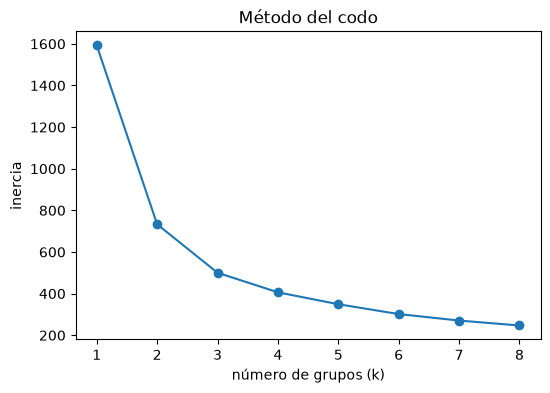

,k,inercia
0,1,1592.0
1,2,733.0
2,3,500.3
3,4,406.3
4,5,349.1
5,6,301.8
6,7,270.6
7,8,246.9


In [5]:
inercias = []
for k in range(1, 9):
    modelo_k = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    inercias.append(modelo_k.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(range(1, 9), inercias, marker="o")
plt.xlabel("número de grupos (k)")
plt.ylabel("inercia")
plt.title("Método del codo")
plt.show()
display(pd.DataFrame({"k": range(1, 9), "inercia": np.round(inercias, 1)}))

**Celda 6 de 14**

In [6]:
siluetas = {}
for k in range(2, 9):
    etiquetas = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Z)
    siluetas[k] = round(silhouette_score(Z, etiquetas), 3)
display(pd.Series(siluetas, name="silueta"))

2    0.500
3    0.375
4    0.348
5    0.335
6    0.299
7    0.293
8    0.290
Name: silueta, dtype: float64

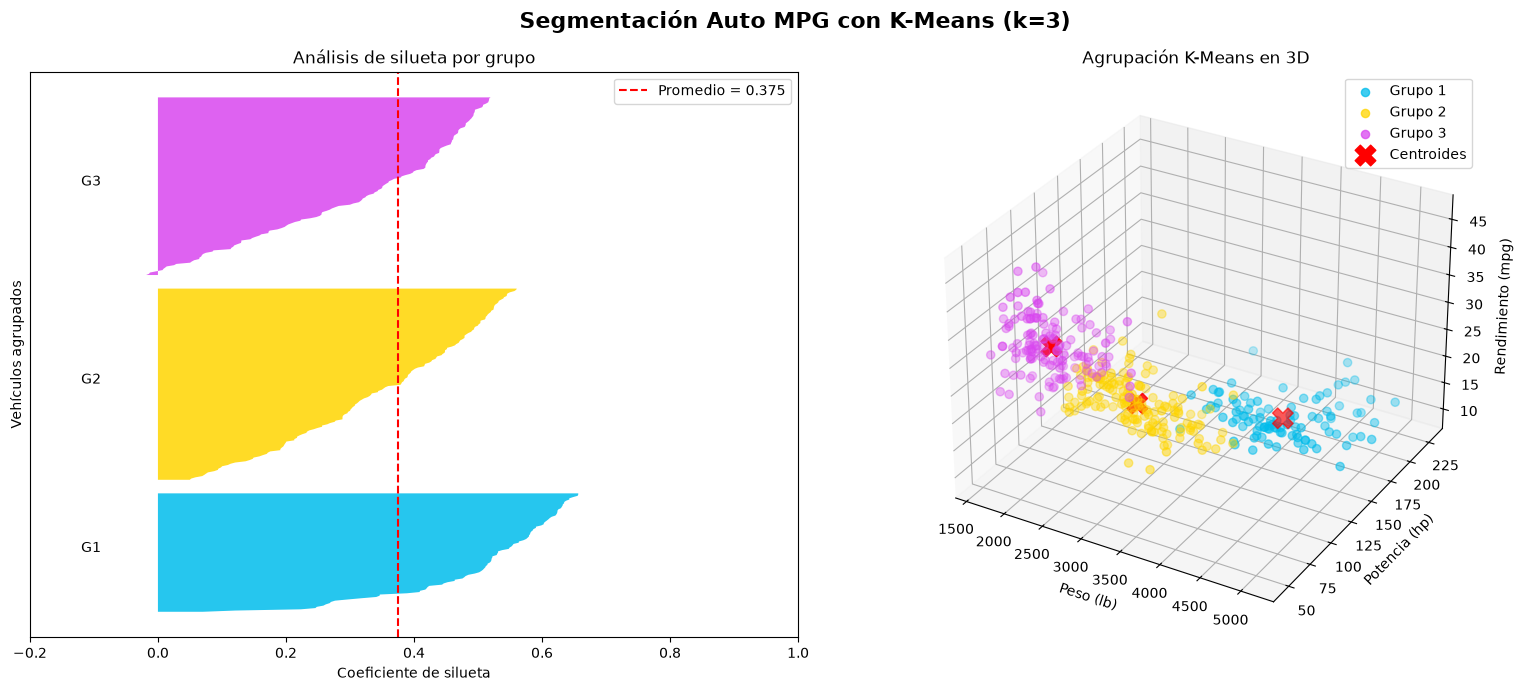

Silueta promedio: 0.375


In [7]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from sklearn.metrics import silhouette_samples, silhouette_score

# Modelo K-Means ya entrenado en el laboratorio
etiquetas = km.labels_
k = km.n_clusters

# Calcular siluetas reales
silueta_media = silhouette_score(Z, etiquetas)
siluetas = silhouette_samples(Z, etiquetas)

fig = plt.figure(figsize=(16, 7))
ax1 = fig.add_subplot(1, 2, 1)
ax2 = fig.add_subplot(1, 2, 2, projection="3d")

colores = ["#00BCEB", "#FFD500", "#D946EF"]

# GRÁFICO 1: SILUETA
y_inferior = 10

for i in range(k):
    valores = np.sort(siluetas[etiquetas == i])
    cantidad = len(valores)
    y_superior = y_inferior + cantidad

    ax1.fill_betweenx(
        np.arange(y_inferior, y_superior),
        0, valores,
        facecolor=colores[i],
        alpha=0.85
    )

    ax1.text(-0.12, y_inferior + cantidad / 2, f"G{i+1}")
    y_inferior = y_superior + 10

ax1.axvline(
    silueta_media,
    color="red",
    linestyle="--",
    label=f"Promedio = {silueta_media:.3f}"
)

ax1.set_title("Análisis de silueta por grupo")
ax1.set_xlabel("Coeficiente de silueta")
ax1.set_ylabel("Vehículos agrupados")
ax1.set_xlim(-0.2, 1)
ax1.set_yticks([])
ax1.legend()

# GRÁFICO 2: AGRUPACIÓN EN 3D
# Se visualizan tres variables originales
for i in range(k):
    grupo = autos[etiquetas == i]

    ax2.scatter(
        grupo["peso"],
        grupo["potencia"],
        grupo["rendimiento_mpg"],
        color=colores[i],
        label=f"Grupo {i+1}",
        s=35,
        alpha=0.75
    )

# Centroides en unidades originales
centros = escalador.inverse_transform(
    km.cluster_centers_
)

ax2.scatter(
    centros[:, 0],
    centros[:, 1],
    centros[:, 3],
    color="red",
    marker="X",
    s=220,
    label="Centroides"
)

ax2.set_xlabel("Peso (lb)")
ax2.set_ylabel("Potencia (hp)")
ax2.set_zlabel("Rendimiento (mpg)")
ax2.set_title("Agrupación K-Means en 3D")
ax2.legend()

fig.suptitle(
    f"Segmentación Auto MPG con K-Means (k={k})",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print(f"Silueta promedio: {silueta_media:.3f}")


**Pregunta 4.** ¿Dónde aparece el codo en la gráfica y qué pasa con la inercia al seguir aumentando k?

**Respuesta:**  
- **Ubicación del codo:** El codo se ubica con claridad en **k = 3** (en la transición entre k=2 y k=3).  
  - Al pasar de k=1 a k=2, la inercia cae abruptamente de 1 592,0 a 733,0 (una reducción de 859,0 unidades).  
  - Al pasar de k=2 a k=3, la inercia cae fuertemente a 500,3 (reducción adicional de 232,7 unidades).  
  - A partir de k=3 la curva experimenta una notable desaceleración: pasar a k=4 solo reduce 94,0 unidades (inercia 406,3), a k=5 reduce 57,2 unidades (inercia 349,1), y para k=8 llega a 246,9.  
- **Comportamiento al seguir aumentando k:** La inercia siempre continúa reduciéndose monótonamente (a mayor número de centroides, menor distancia promedio de cada punto a su centro más cercano), pero con caídas marginales cada vez más pequeñas (rendimientos decrecientes), lo cual indica que añadir más clusters solo aporta ganancias insignificantes a costa de sobrefragmentar los datos.

**Pregunta 5.** Compare las siluetas de k = 2, 3 y 4. ¿Qué k elige y por qué, aunque k = 2 tenga la mayor silueta?

**Respuesta:**  
- **Comparación de siluetas:**  
  - Para **k = 2**: silueta promedio = **0,500**  
  - Para **k = 3**: silueta promedio = **0,375**  
  - Para **k = 4**: silueta promedio = **0,348**  
- **Elección fundamentada:** Se elige **k = 3**.  
  - **¿Por qué no k = 2?** A pesar de que k=2 ostenta la silueta más alta, para el negocio representa una partición excesivamente burda y binaria (autos pesados vs. autos ligeros), omitiendo toda la categoría intermedia de vehículos que constituye el núcleo de la flota operativa.  
  - **Ventajas de k = 3:** Presenta una silueta sólida y bien equilibrada (0,375), coincide con el punto de inflexión del codo y genera tres perfiles claramente interpretables y accionables en la toma de decisiones ("Livianos y eficientes", "Intermedios", y "Pesados y de alta potencia").  
  - **¿Por qué no k = 4?** En k=4 la silueta decae a 0,348 y, como muestra el Reto 2, subdivide de forma artificial el grupo de autos livianos sin aportar una distinción operativa real.

### Ejercicio 4 - Perfiles y nombres de los segmentos

**Fase CRISP-DM.** Modelado (celda 7) y evaluación (celdas 8 y 9).

Con k = 3 se asigna el segmento a cada auto y se calcula el perfil: el promedio de cada variable por segmento, en unidades originales, que es lo que se puede leer en lenguaje de negocio. Los nombres se asignan según el peso promedio de cada segmento, de modo que no dependen del número que K-Means le dio al grupo.

**Se solicita.** Ejecute las celdas 7, 8 y 9.

**Celda 7 de 14**

In [8]:
K = 3
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Z)
autos["segmento"] = km.labels_

perfil = autos.groupby("segmento")[variables].mean().round(1)
perfil["autos"] = autos["segmento"].value_counts().sort_index()
perfil["% del total"] = (perfil["autos"] / len(autos) * 100).round(1)
display(perfil)

,peso,potencia,aceleracion,rendimiento_mpg,autos,% del total
segmento,,,,,,
0,4144.0,161.8,12.6,14.5,97,24.4
1,2974.3,98.0,16.2,21.3,156,39.2
2,2181.2,72.7,16.8,31.9,145,36.4


**Celda 8 de 14**

In [9]:
orden = perfil["peso"].sort_values().index
nombres = dict(zip(orden, ["Livianos y eficientes", "Intermedios", "Pesados y de alta potencia"]))
autos["nombre_segmento"] = autos["segmento"].map(nombres)

display(pd.crosstab(autos["nombre_segmento"], autos["origen"]))

origen,Europa,Japón,USA
nombre_segmento,,,
Intermedios,24,23,109
Livianos y eficientes,46,56,43
Pesados y de alta potencia,0,0,97


**Celda 9 de 14**

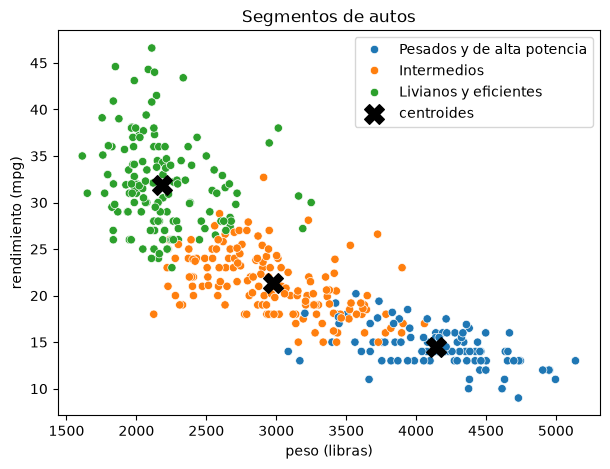

In [10]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=autos, x="peso", y="rendimiento_mpg", hue="nombre_segmento")
centros = escalador.inverse_transform(km.cluster_centers_)
plt.scatter(centros[:, 0], centros[:, 3], marker="X", s=200, color="black", label="centroides")
plt.xlabel("peso (libras)")
plt.ylabel("rendimiento (mpg)")
plt.title("Segmentos de autos")
plt.legend()
plt.show()

**Pregunta 6.** Describa el perfil de cada segmento con sus cifras: peso, potencia, rendimiento y tamaño.

**Respuesta:**  
1. **Livianos y eficientes (Segmento 2):**  
   - **Tamaño:** 145 vehículos (36,4 % de la flota).  
   - **Peso promedio:** 2 181,2 lb.  
   - **Potencia promedio:** 72,7 hp.  
   - **Aceleración promedio:** 16,8 segundos (0-60 mph).  
   - **Rendimiento promedio:** 31,9 mpg.  
   - *Perfil:* Automóviles compactos, livianos, de baja potencia mecánica y excelente rendimiento de combustible.  
2. **Intermedios (Segmento 1):**  
   - **Tamaño:** 156 vehículos (39,2 % de la flota, segmento mayoritario).  
   - **Peso promedio:** 2 974,3 lb.  
   - **Potencia promedio:** 98,0 hp.  
   - **Aceleración promedio:** 16,2 segundos.  
   - **Rendimiento promedio:** 21,3 mpg.  
   - *Perfil:* Vehículos de masa media y motor intermedio, que logran un balance equilibrado entre capacidad de transporte y consumo moderado.  
3. **Pesados y de alta potencia (Segmento 0):**  
   - **Tamaño:** 97 vehículos (24,4 % de la flota).  
   - **Peso promedio:** 4 144,0 lb.  
   - **Potencia promedio:** 161,8 hp.  
   - **Aceleración promedio:** 12,6 segundos (la respuesta más rápida).  
   - **Rendimiento promedio:** 14,5 mpg.  
   - *Perfil:* Vehículos de gran tamaño, motores potentes y alta capacidad de respuesta o carga, con un consumo de combustible elevado.

**Pregunta 7.** ¿Por qué se eligieron esos nombres? ¿Cómo se reparte el origen dentro de cada segmento y puede decirse que el origen causa el segmento?

**Respuesta:**  
- **Justificación de los nombres:** Se definieron combinando las dos dimensiones clave del negocio: la masa/tamaño físico del auto ("liviano", "intermedio", "pesado") y su desempeño mecánico/energético ("eficiente", "alta potencia"). Además, al ordenarse por peso promedio mediante código, el nombre asignado es determinista y no depende del número arbitrario asignado por K-Means.  
- **Distribución por origen:**  
  - *Livianos y eficientes:* Predominan notablemente **Japón (56)** y **Europa (46)**, frente a 43 de USA.  
  - *Intermedios:* Predomina marcadamente **USA (109)**, complementado por Europa (24) y Japón (23).  
  - *Pesados y de alta potencia:* Procede en su totalidad de **USA (97 autos, 100 %)**; ningún vehículo europeo ni japonés ingresa a este grupo.  
- **Causalidad:** **No puede decirse que el origen cause el segmento.** El origen geográfico es una variable cualitativa contextual vinculada al entorno industrial e histórico de la época (en los años 70 los fabricantes estadounidenses se enfocaban en vehículos pesados y potentes para autopistas amplias y gasolina barata, mientras Europa y Japón priorizaban autos compactos y económicos). Se trata de una correlación tecnológica e industrial, no de una causalidad física.

**Pregunta 8.** ¿Qué muestra el gráfico de dispersión con los centroides? ¿Los grupos están separados con nitidez?

**Respuesta:**  
- **Interpretación del gráfico:** El diagrama muestra con claridad la relación inversa y no lineal entre peso y rendimiento (a mayor peso en libras, menor es el rendimiento en mpg). Los centroides (representados con "X" negras en coordenadas originales: [2 181,2 lb; 31,9 mpg], [2 974,3 lb; 21,3 mpg] y [4 144,0 lb; 14,5 mpg]) sintetizan y fijan el punto gravitacional de cada conglomerado a lo largo de la curva de distribución.  
- **Nitidez de separación:** La separación global es muy consistente. El grupo de "Pesados y de alta potencia" se encuentra claramente aislado en la zona inferior derecha. Por su parte, entre "Livianos y eficientes" e "Intermedios" se aprecia una zona de contacto continuo en torno a 2 500-2 800 lb, lo cual refleja la realidad de una distribución continua en el mercado automotriz donde el algoritmo traza fronteras de partición óptimas para la gestión de flota.

### Ejercicio 5 - Registrar los segmentos en SQLite

**Fase CRISP-DM.** Despliegue.

El segmento se guarda como una columna nueva en autos_limpio con to_sql(). Así cualquier persona puede consultar los segmentos con SQL sin repetir el modelo.

**Se solicita.** Ejecute la celda 10.

**Celda 10 de 14**

In [11]:
autos.to_sql("autos_limpio", conexion, index=False, if_exists="replace")

consulta = """SELECT nombre_segmento,
       COUNT(*) AS autos,
       ROUND(AVG(rendimiento_mpg), 1) AS mpg_promedio,
       ROUND(AVG(peso), 0) AS peso_promedio
FROM autos_limpio
GROUP BY nombre_segmento
ORDER BY peso_promedio;"""
display(pd.read_sql_query(consulta, conexion))

,nombre_segmento,autos,mpg_promedio,peso_promedio
0,Livianos y eficientes,145,31.9,2181.0
1,Intermedios,156,21.3,2974.0
2,Pesados y de alta potencia,97,14.5,4144.0


**Pregunta 9.** ¿Qué devuelve la consulta y cómo comprueba que la columna del segmento quedó registrada? ¿Por qué conviene guardarla en SQLite?

**Respuesta:**  
- **Resultado de la consulta:** Devuelve una tabla agrupada de 3 filas con las columnas `nombre_segmento`, `autos`, `mpg_promedio` y `peso_promedio`, ordenada por peso promedio:  
  1. *Livianos y eficientes:* 145 autos, 31,9 mpg, 2 181 lb.  
  2. *Intermedios:* 156 autos, 21,3 mpg, 2 974 lb.  
  3. *Pesados y de alta potencia:* 97 autos, 14,5 mpg, 4 144 lb.  
- **Comprobación:** Se comprueba directamente porque la sentencia SQL ejecuta sin errores una cláusula `SELECT nombre_segmento ... GROUP BY nombre_segmento` sobre la tabla `autos_limpio`, confirmando que el nuevo atributo fue creado, persistido e indexado satisfactoriamente en la base de datos relacional.  
- **Conveniencia de guardarla en SQLite:** Representa la concreción de la **Fase 6 de CRISP-DM (Despliegue)**. Al almacenar los segmentos en SQLite, cualquier usuario de negocio, analista o sistema gerencial de flota puede consultar, filtrar y generar reportes operativos mediante simples consultas SQL estándar, sin necesidad de ejecutar scripts en Python, instalar librerías de machine learning ni recalcular el modelo K-Means cada vez.

## Actividad 3 - Usar los segmentos en la decisión

**Fase CRISP-DM.** Despliegue: uso del resultado en la decisión.

La gerencia tiene tres autos candidatos de compra (los de la semana 6, con su rendimiento estimado). Ejecute la celda 11, que asigna cada candidato a un segmento con km.predict(), y complete la tabla con los resultados.

**Celda 11 de 14**

In [12]:
candidatos = pd.DataFrame({
    "candidato": ["A", "B", "C"],
    "peso": [2200, 3000, 4200],
    "potencia": [80, 110, 160],
    "aceleracion": [16, 15, 12],
    "rendimiento_mpg": [33.5, 26.5, 16.7]})

asignado = km.predict(escalador.transform(candidatos[variables]))
candidatos["segmento"] = pd.Series(asignado).map(nombres).values
display(candidatos)

C:\Users\ERICK\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


,candidato,peso,potencia,aceleracion,rendimiento_mpg,segmento
0,A,2200,80,16,33.5,Livianos y eficientes
1,B,3000,110,15,26.5,Intermedios
2,C,4200,160,12,16.7,Pesados y de alta potencia


| Candidato | Peso (lb) | Potencia | Rendimiento (mpg) | Segmento |
|---|---|---|---|---|
| A | 2 200 | 80 | 33,5 | Livianos y eficientes |
| B | 3 000 | 110 | 26,5 | Intermedios |
| C | 4 200 | 160 | 16,7 | Pesados y de alta potencia |

**A.** ¿A qué segmento pertenece cada candidato y qué tipo de uso de la flota sugiere cada segmento?

**Respuesta:**  
- **Candidato A (2 200 lb, 80 hp, 33,5 mpg) → Segmento: *Livianos y eficientes***:  
  - *Uso sugerido en la flota:* Rutas urbanas congestionadas, transporte administrativo, supervisión y servicios de mensajería/reparto ligero de última milla. Se prioriza el bajo consumo de combustible y la facilidad de desplazamiento y estacionamiento.  
- **Candidato B (3 000 lb, 110 hp, 26,5 mpg) → Segmento: *Intermedios***:  
  - *Uso sugerido en la flota:* Vehículo versátil de propósito general y uso mixto. Indicado para transporte de personal técnico con herramientas, visitas interurbanas y viajes en carretera, equilibrando confort, capacidad de carga moderada y consumo razonable.  
- **Candidato C (4 200 lb, 160 hp, 16,7 mpg) → Segmento: *Pesados y de alta potencia***:  
  - *Uso sugerido en la flota:* Operaciones pesadas y demandantes: transporte de carga pesada, arrastre de remolques o rutas en geografía andina con pendientes pronunciadas y caminos de difícil acceso donde se requiere máxima potencia y tracción, asumiendo su mayor gasto de combustible.

**B.** Ubique en su fase de CRISP-DM tres pasos de este laboratorio: el escalado, la silueta y el registro en SQLite. Si la gerencia dijera que los tres segmentos no le sirven para decidir la compra, ¿a qué fase volvería y qué cambiaría?

**Respuesta:**  
- **Ubicación en fases CRISP-DM:**  
  1. *El escalado con StandardScaler:* Fase 3 - **Preparación de los datos** (Data Preparation).  
  2. *El análisis de silueta:* Fase 5 - **Evaluación** (Evaluation).  
  3. *El registro en la base de datos SQLite:* Fase 6 - **Despliegue** (Deployment).  
- **Ciclo iterativo ante rechazo gerencial:**  
  Si la gerencia concluye que tres grupos son inadecuados para orientar las adquisiciones, el proceso iterativo de CRISP-DM exige regresar a la **Fase 1: Comprensión del negocio** (Business Understanding). Allí se deberán reformular las preguntas y criterios operativos clave (por ejemplo: si se necesita segmentar por capacidad volumétrica de carga, tipo de tracción 4x4, costo de mantenimiento preventivo o vida útil proyectada).  
  Posteriormente se regresará a la **Fase 3 - Preparación de los datos** para incorporar nuevas variables explicativas (como cilindrada, año de modelo, dimensiones físicas o costo por km) o depurar restricciones, y a la **Fase 4: Modelado** para calibrar un valor distinto de k (ej. k = 4 o 5) o evaluar métodos jerárquicos o de densidad.

## Reto de aplicación y retroalimentación

Indicaciones. Cada reto presenta el código ya escrito: ejecútelo, identifique qué hace cada instrucción e interprete el resultado con cifras. No se trata de cambiar el código sino de leerlo y explicarlo.

### Reto 1 - ¿Y si no se escala?

Dirección técnica pregunta si el escalado es de verdad necesario. Se ajusta K-Means con las variables originales y se compara.

**Celda 12 de 14**

In [13]:
km_sin = KMeans(n_clusters=3, n_init=10, random_state=42).fit(autos[variables])
print("Silueta sin escalar:", round(silhouette_score(autos[variables], km_sin.labels_), 3))
print("Silueta con escalado:", round(silhouette_score(Z, km.labels_), 3))
display(autos.assign(grupo_sin_escalar=km_sin.labels_)
        .groupby("grupo_sin_escalar")[variables].mean().round(1))

Silueta sin escalar: 0.592
Silueta con escalado: 0.375


,peso,potencia,aceleracion,rendimiento_mpg
grupo_sin_escalar,,,,
0,2217.7,77.3,16.4,29.8
1,3157.8,105.5,15.9,20.8
2,4242.4,157.7,13.5,14.6


**Pregunta de cierre.** ¿Qué pasa con la silueta y con los grupos al no escalar? ¿Por qué una silueta mayor no significa mejores segmentos?

**Respuesta:**  
- **Efecto en la silueta y en los grupos sin escalar:** La silueta promedio se eleva numéricamente a **0,592** (frente a **0,375** obtenido con datos escalados). No obstante, al analizar los promedios de las variables en los tres grupos resultantes (Grupo 0: 2 217,7 lb; Grupo 1: 3 157,8 lb; Grupo 2: 4 242,4 lb), los clusters quedaron determinados prácticamente de forma unidimensional sobre el `peso`. La variable `aceleracion` promedia valores casi indistinguibles entre grupos (16,4, 15,9 y 13,5 s), habiendo sido totalmente ignorada por el modelo.  
- **Por qué una silueta mayor no implica mejores segmentos:** El coeficiente de silueta mide la separación relativa en el espacio de distancias suministrado. Al no escalar, la enorme varianza y escala del `peso` (con rango de miles frente a decenas) domina de forma absoluta la suma de distancias euclidianas al cuadrado, proyectando los datos a un solo eje y creando cortes muy limpios sobre el peso que inflan la silueta. Sin embargo, esto genera una segmentación deformada e inútil para el negocio, ya que pierde la riqueza multidimensional del vehículo al anular la influencia de la potencia, la aceleración y la eficiencia energética.

### Reto 2 - ¿Tres o cuatro segmentos?

Marketing propone un grupo más. Se ajusta K-Means con k = 4 y se compara con k = 3.

**Celda 13 de 14**

In [14]:
km4 = KMeans(n_clusters=4, n_init=10, random_state=42).fit(Z)
print("Silueta con k = 3:", round(silhouette_score(Z, km.labels_), 3))
print("Silueta con k = 4:", round(silhouette_score(Z, km4.labels_), 3))

perfil4 = autos.assign(grupo4=km4.labels_).groupby("grupo4")[variables].mean().round(1)
perfil4["autos"] = np.bincount(km4.labels_)
display(perfil4)

Silueta con k = 3: 0.375
Silueta con k = 4: 0.348


,peso,potencia,aceleracion,rendimiento_mpg,autos
grupo4,,,,,
0,3157.7,98.4,17.0,20.1,109
1,2358.0,86.7,14.7,27.9,118
2,4147.1,162.1,12.6,14.5,96
3,2155.6,66.6,18.6,33.2,75


**Pregunta de cierre.** ¿Cómo cambian la silueta y los perfiles con k = 4? ¿Convendría pasar a cuatro segmentos?

**Respuesta:**  
- **Comportamiento de la silueta y perfiles con k = 4:**  
  - La silueta promedio desciende de **0,375 (k = 3)** a **0,348 (k = 4)**, evidenciando una menor separación y mayor solapamiento en los límites entre clusters contiguos.  
  - Al inspeccionar los perfiles: el grupo pesado se mantiene definido (Grupo 2: 4 147,1 lb; 162,1 hp; 96 autos) y el intermedio también (Grupo 0: 3 157,7 lb; 98,4 hp; 109 autos); sin embargo, el grupo de autos livianos y económicos se fragmenta de forma forzada en dos subgrupos con perfiles redundantes: Grupo 3 (2 155,6 lb; 66,6 hp; 33,2 mpg; 75 autos) y Grupo 1 (2 358,0 lb; 86,7 hp; 27,9 mpg; 118 autos).  
- **Evaluación de conveniencia:** **No conviene pasar a cuatro segmentos.** Dividir los autos compactos en dos variantes menores no aporta ninguna ventaja táctica para la gestión de flota de AutoFlota Andina y, por el contrario, entorpece las políticas de adquisición. Por el principio de parsimonia, **k = 3 es la solución metodológica y operativamente óptima**.

### Reto 3 - ¿Son estables los grupos?

El índice de Rand ajustado (ARI) mide el acuerdo entre dos agrupaciones: 1 es acuerdo perfecto y valores cercanos a 0 indican que no coinciden. Se compara el ajuste del laboratorio con otro hecho con otra semilla y una sola inicialización.

**Celda 14 de 14**

In [15]:
otra = KMeans(n_clusters=3, n_init=1, random_state=7).fit(Z)
print("Acuerdo entre los dos ajustes (ARI):", round(adjusted_rand_score(km.labels_, otra.labels_), 3))
print("Inercia del primero:", round(km.inertia_, 1), "| del segundo:", round(otra.inertia_, 1))

Acuerdo entre los dos ajustes (ARI): 1.0
Inercia del primero: 500.3 | del segundo: 500.3


**Pregunta de cierre.** ¿Qué indica el ARI y por qué se usa n_init = 10?

**Respuesta:**  
- **Significado del ARI:** El índice calculado es **ARI = 1,0**, lo que demuestra una **concordancia perfecta y absoluta (100 %)** entre la partición obtenida por el modelo principal (n_init=10, random_state=42) y el modelo secundario (n_init=1, random_state=7), manteniendo idéntica inercia de **500,3**. Esto confirma que los tres segmentos identificados representan conglomerados densos, naturales y altamente estables en los datos estandarizados.  
- **Importancia de usar `n_init = 10`:** Debido a que K-Means emplea una heurística iterativa con inicialización aleatoria de centroides, una sola corrida corre el riesgo de converger en un óptimo local subóptimo con distorsión de grupos e inercia elevada. Utilizar `n_init = 10` asegura ejecutar 10 inicializaciones independientes con diferentes posiciones de partida y conservar aquella con la inercia mínima global, garantizando robustez y repetibilidad en los hallazgos.

## Conclusiones

Escriba tres conclusiones técnicas y de negocio de este laboratorio.

1. **Conclusión Técnica (Preparación de datos y sensibilidad de escala):** El preprocesamiento mediante estandarización (`StandardScaler`) es un requisito técnico fundamental e ineludible en algoritmos fundamentados en distancias euclidianas como K-Means. Omitir el escalado distorsiona la métrica de proximidad geométrica, permitiendo que la variable con mayor orden de magnitud (`peso`) monopolice el agrupamiento y produzca una silueta falsamente elevada (0,592), mientras invisibiliza por completo atributos dinámicos esenciales como la aceleración y el rendimiento en combustible.  
2. **Conclusión Metodológica (Evaluación integral y parsimonia de clusters):** La selección de \(k\) debe responder a una evaluación armónica entre métricas cuantitativas y viabilidad operativa. Si bien k=2 presentó la mayor silueta (0,500), resultaba operativamente estéril por su binarismo extremo; a su vez, k=4 generaba subgrupos redundantes reduciendo la silueta a 0,348. En consecuencia, k=3 se consolidó como la configuración óptima al conciliar el punto de inflexión del codo (inercia 500,3), una silueta equilibrada (0,375), perfiles diferenciados y una estabilidad absoluta ante reinicios (ARI = 1,0).  
3. **Conclusión de Negocio y Despliegue (AutoFlota Andina y CRISP-DM):** La articulación metódica de las fases de CRISP-DM permitió pasar con éxito del análisis exploratorio no supervisado al despliegue operacional en SQLite (`autos_limpio`). Esta solución analítica faculta a la gerencia de AutoFlota Andina a catalogar nuevos vehículos candidatos en tres segmentos operativos transparentes ("Livianos y eficientes", "Intermedios", y "Pesados y de alta potencia"), alineando estratégicamente la asignación de cada unidad según la severidad de la ruta y optimizando de forma tangible el presupuesto de compra y el gasto de combustible.